# 08 — Advanced Models and Hyperparameter Optimisation
**Day 8 · Phase 4**

### Candidates
| Model | Idea | Key hyperparameters |
|---|---|---|
| **Ridge** | Linear regression + L2 penalty (shrinks coefficients; stabilises correlated features) | `alpha` (penalty strength) |
| **Random Forest** | Average of many deep trees on bootstrap samples with random feature subsets | `max_depth`, `min_samples_leaf`, `max_features` |
| **Gradient Boosting** | Trees added sequentially, each fitting the previous ensemble's errors | `n_estimators`, `learning_rate`, `max_depth`, `min_samples_leaf`, `subsample` |
| **HistGradientBoosting** | Faster boosting on binned features, built-in L2 regularisation | `max_iter`, `learning_rate`, `max_depth`, `min_samples_leaf`, `l2_regularization` |
| **Ridge + GB average** | Equal-weight average of a linear and a boosting model (justified below) | none extra |

### Search strategy (not excessive)
- **GridSearchCV** for Ridge: 2 parameters, small grid, exhaustive search is cheap.
- **RandomizedSearchCV** (30–40 draws) for tree ensembles: their spaces are larger and random search covers them
  efficiently. Budgets are kept modest: with 419 rows, chasing tiny CV gains would mostly fit noise in the folds.
- Every search scores **MAE under grouped 5-fold CV**, with preprocessing inside the pipeline.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

import time
from scipy.stats import loguniform, randint
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingRegressor, RandomForestRegressor,
                              VotingRegressor)
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from functools import partial

from src.train import (load_model_ready_data, xy, group_cv, build_pipeline, advanced_models, tuned_models,
                       RIDGE_PARAMS, GB_PARAMS, HGB_PARAMS, RF_PARAMS)
from src.feature_engineering import make_preprocessor
from src.evaluate import compare_models

train, test = load_model_ready_data()
X_tr, y_tr, g_tr = xy(train)
CV, SCORING = group_cv(), "neg_mean_absolute_error"
search_log = []

def record(name, search, seconds):
    best = {k.split("__")[-1]: (round(float(v), 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
    search_log.append({"model": name, "search": type(search).__name__, "candidates": len(search.cv_results_["params"]),
                       "best_cv_MAE": -search.best_score_, "seconds": round(seconds, 1), "best_params": best})
    print(f"{name}: best CV MAE ₹{-search.best_score_:,.0f} in {seconds:.0f}s → {best}")

## 1. Default-parameter comparison (before tuning)

In [2]:
default_results = compare_models(advanced_models(), X_tr, y_tr, CV, g_tr)
default_results[["train_MAE", "cv_MAE", "cv_MAE_std", "cv_R2", "fit_time_s"]].round(3)

,train_MAE,cv_MAE,cv_MAE_std,cv_R2,fit_time_s
model,,,,,
Ridge,"1,797.761","2,408.210",781.573,0.828,0.019
Gradient Boosting,753.010,"2,810.053",771.807,0.749,0.066
Random Forest,444.833,"2,958.714",995.984,0.704,0.292
HistGradientBoosting,"1,079.755","2,961.417","1,075.131",0.730,0.097


**Interpretation.** With default settings Ridge is ahead (₹2,408) and the tree ensembles trail (₹2,810–2,961) with
very low training error, the same overfitting pattern as Day 7. Tuning should mostly add **regularisation** to the
tree models (shallower trees, bigger leaves, slower learning).

## 2. Ridge — GridSearchCV

Ridge: best CV MAE ₹2,331 in 4s → {'alpha': 0.01, 'min_frequency': 5}


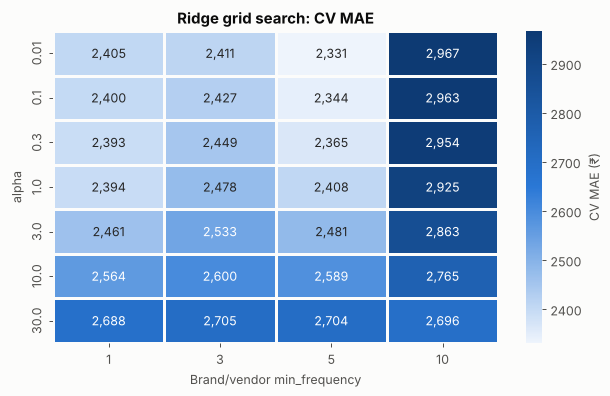

In [3]:
t0 = time.perf_counter()
ridge_search = GridSearchCV(
    build_pipeline(Ridge(), scale_numeric=True),
    {"model__regressor__alpha": [0.01, 0.1, 0.3, 1, 3, 10, 30],
     "prep__encode__cat__onehot__min_frequency": [1, 3, 5, 10]},
    cv=CV, scoring=SCORING, n_jobs=1).fit(X_tr, y_tr, groups=g_tr)
record("Ridge", ridge_search, time.perf_counter() - t0)

grid = pd.DataFrame(ridge_search.cv_results_)
heat = grid.pivot_table(index="param_model__regressor__alpha", columns="param_prep__encode__cat__onehot__min_frequency",
                        values="mean_test_score").mul(-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap=SEQUENTIAL, ax=ax, cbar_kws={"label": "CV MAE (₹)"}, linewidths=1, linecolor="#fcfcfb")
ax.set(title="Ridge grid search: CV MAE", xlabel="Brand/vendor min_frequency", ylabel="alpha"); ax.grid(False)
fig.tight_layout(); save_fig(fig, "tuning_ridge_grid")

**Interpretation.** Small `alpha` (weak penalty) works best: the 29 features aren't too many for 419 rows once
they're scaled, so heavy shrinkage only adds bias. `min_frequency=5` (the Day 4 default) is chosen. The surface is flat
across the top rows, so the exact alpha matters little; we keep `alpha=0.01`.

## 3. Random Forest — RandomizedSearchCV

In [4]:
t0 = time.perf_counter()
rf_search = RandomizedSearchCV(
    build_pipeline(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__regressor__max_depth": [None, 4, 6, 8, 12],
     "model__regressor__min_samples_leaf": randint(1, 10),
     "model__regressor__max_features": [0.3, 0.5, 0.7, 1.0]},
    n_iter=30, cv=CV, scoring=SCORING, random_state=RANDOM_STATE, n_jobs=1).fit(X_tr, y_tr, groups=g_tr)
record("Random Forest", rf_search, time.perf_counter() - t0)

Random Forest: best CV MAE ₹2,807 in 58s → {'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 2}


## 4. Gradient Boosting — RandomizedSearchCV

In [5]:
t0 = time.perf_counter()
gb_search = RandomizedSearchCV(
    build_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    {"model__regressor__n_estimators": randint(100, 600),
     "model__regressor__learning_rate": loguniform(0.01, 0.2),
     "model__regressor__max_depth": [2, 3, 4],
     "model__regressor__subsample": [0.6, 0.8, 1.0],
     "model__regressor__min_samples_leaf": randint(1, 15)},
    n_iter=40, cv=CV, scoring=SCORING, random_state=RANDOM_STATE, n_jobs=1).fit(X_tr, y_tr, groups=g_tr)
record("Gradient Boosting", gb_search, time.perf_counter() - t0)

Gradient Boosting: best CV MAE ₹2,427 in 41s → {'learning_rate': 0.1604, 'max_depth': 3, 'min_samples_leaf': 9, 'n_estimators': 127, 'subsample': 1.0}


## 5. HistGradientBoosting — RandomizedSearchCV

In [6]:
t0 = time.perf_counter()
hgb_search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    {"model__regressor__max_iter": randint(100, 600),
     "model__regressor__learning_rate": loguniform(0.01, 0.2),
     "model__regressor__max_depth": [None, 3, 4, 6],
     "model__regressor__min_samples_leaf": randint(5, 30),
     "model__regressor__l2_regularization": loguniform(1e-3, 10)},
    n_iter=40, cv=CV, scoring=SCORING, random_state=RANDOM_STATE, n_jobs=1).fit(X_tr, y_tr, groups=g_tr)
record("HistGradientBoosting", hgb_search, time.perf_counter() - t0)

search_df = pd.DataFrame(search_log)
search_df.to_csv(PROJECT_ROOT / "reports" / "tuning_results.csv", index=False)
search_df

HistGradientBoosting: best CV MAE ₹2,469 in 47s → {'l2_regularization': 0.0062, 'learning_rate': 0.0842, 'max_depth': 4, 'max_iter': 388, 'min_samples_leaf': 9}


,model,search,candidates,best_cv_MAE,seconds,best_params
0,Ridge,GridSearchCV,28,"2,331.415",4.300,"{'alpha': 0.01, 'min_frequency': 5}"
1,Random Forest,RandomizedSearchCV,30,"2,806.883",58.100,"{'max_depth': 8, 'max_features': 0.3, 'min_sam..."
2,Gradient Boosting,RandomizedSearchCV,40,"2,426.604",41.000,"{'learning_rate': 0.1604, 'max_depth': 3, 'min..."
3,HistGradientBoosting,RandomizedSearchCV,40,"2,469.015",47.200,"{'l2_regularization': 0.0062, 'learning_rate':..."


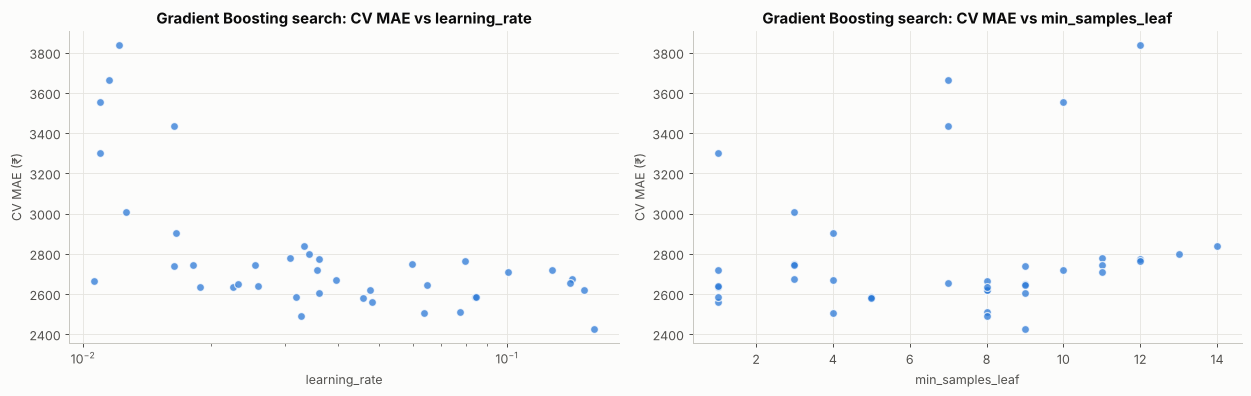

In [7]:
gb_cv = pd.DataFrame(gb_search.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, param, label in [(axes[0], "param_model__regressor__learning_rate", "learning_rate"),
                         (axes[1], "param_model__regressor__min_samples_leaf", "min_samples_leaf")]:
    ax.scatter(gb_cv[param].astype(float), -gb_cv["mean_test_score"], s=40, color=PRIMARY, alpha=0.75, edgecolor="white")
    ax.set(title=f"Gradient Boosting search: CV MAE vs {label}", xlabel=label, ylabel="CV MAE (₹)")
axes[0].set_xscale("log")
fig.tight_layout(); save_fig(fig, "tuning_gb_search")

**Interpretation.**
- Tuning moves every tree model in the regularising direction: the forest prefers `max_features=0.3` and limited
  depth; boosting prefers shallow trees (depth 3–4) with **larger leaves (`min_samples_leaf≈9`)**, which stops the
  model from fitting individual phones.
- Tuned boosting improves from ~₹2,810–2,960 (defaults) to **~₹2,430–2,520** and the forest to ~₹2,810, but **none
  beats the tuned Ridge (₹2,331)** on its own.
- In the scatter, results vary by several hundred rupees between configurations with similar settings, which is the
  CV noise level. The search's best score is therefore slightly optimistic (it's the maximum of many noisy estimates).
  You can see this in §6: re-running GB with the *rounded* best parameters gives ₹2,469 instead of the search's ₹2,427.

## 6. Combining a linear and a boosting model
Ridge and boosting make **different kinds of errors**. Ridge is smooth and extrapolates (in log space) to phones with
more extreme specs; boosting captures thresholds and interactions (e.g. battery × tier) but can't extrapolate beyond
the training range. Averaging two good models with different error patterns usually reduces variance. The weights
are fixed at 0.5/0.5 rather than tuned, to avoid fitting another parameter to noisy folds.

In [8]:
tuned = tuned_models()      # tuned parameters (rounded from the searches above) are stored in src/train.py
tuned_results = compare_models(tuned, X_tr, y_tr, CV, g_tr)
print("Parameters used:", {"Ridge": RIDGE_PARAMS, "GB": GB_PARAMS, "HGB": HGB_PARAMS, "RF": RF_PARAMS}, sep="\n")
tuned_results[["train_MAE", "cv_MAE", "cv_MAE_std", "train_RMSE", "cv_RMSE", "train_R2", "cv_R2", "fit_time_s"]].round(3)

Parameters used:
{'Ridge': {'alpha': 0.01}, 'GB': {'n_estimators': 127, 'learning_rate': 0.16, 'max_depth': 3, 'min_samples_leaf': 9, 'subsample': 1.0}, 'HGB': {'max_iter': 388, 'learning_rate': 0.084, 'max_depth': 4, 'min_samples_leaf': 9, 'l2_regularization': 0.0062}, 'RF': {'n_estimators': 300, 'max_depth': 8, 'max_features': 0.3, 'min_samples_leaf': 2}}


,train_MAE,cv_MAE,cv_MAE_std,train_RMSE,cv_RMSE,train_R2,cv_R2,fit_time_s
model,,,,,,,,
Ridge + GB average,"1,136.431","2,170.562",615.804,"1,673.181","4,067.131",0.975,0.847,0.115
Ridge,"1,750.038","2,331.415",621.104,"2,656.611","4,023.008",0.938,0.845,0.019
Gradient Boosting (tuned),763.658,"2,468.637",736.110,"1,228.034","4,632.050",0.987,0.793,0.092
HistGradientBoosting (tuned),472.303,"2,516.450",856.115,801.216,"4,673.574",0.994,0.780,0.245
Random Forest (tuned),"1,151.035","2,806.883","1,023.518","2,141.588","5,156.712",0.960,0.756,0.343


**Interpretation.** The **Ridge + GB average has the lowest CV error (≈ ₹2,171)**, about ₹160 better than Ridge alone
and ₹300 better than tuned GB alone, with the lowest fold-to-fold spread. Its training error (≈ ₹1,136) sits between
Ridge's and GB's, i.e. it overfits less than boosting while fitting more than Ridge. Its R² equals Ridge's (0.847 vs
0.845) and its CV RMSE is marginally *higher* (₹4,067 vs ₹4,023): the average reduces typical errors, but the largest
misses (premium phones) remain about as large.

The improvement is smaller than one fold standard deviation (~₹600), so CV alone can't prove it is better. Day 9
checks it on the untouched test set before the final choice.

## 7. Feature-set comparison for the tuned models
Day 5 found that *default* boosting improved with 8–10 MI-selected features. Is that still true after tuning? The
selector sits inside the pipeline, so it is re-fitted on each fold.

In [9]:
mi = partial(mutual_info_regression, random_state=RANDOM_STATE)
def gb_pipe(k=None):
    steps = [("prep", make_preprocessor())]
    if k:
        steps.append(("select", SelectKBest(mi, k=k)))
    steps.append(("gb", GradientBoostingRegressor(random_state=RANDOM_STATE, **GB_PARAMS)))
    return Pipeline(steps)
def ens(k=None):
    ridge = Pipeline([("prep", make_preprocessor(scale_numeric=True)), ("ridge", Ridge(**RIDGE_PARAMS))])
    return TransformedTargetRegressor(VotingRegressor([("ridge", ridge), ("gb", gb_pipe(k))]),
                                      func=np.log1p, inverse_func=np.expm1, check_inverse=False)
log_t = lambda p: TransformedTargetRegressor(p, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
feature_sets = {
    "Tuned GB · all features": log_t(gb_pipe()),
    "Tuned GB · MI top-10": log_t(gb_pipe(10)),
    "Tuned GB · MI top-8": log_t(gb_pipe(8)),
    "Ridge + GB · all features": ens(),
    "Ridge + GB(MI top-10)": ens(10),
    "Tuned GB · all features · raw-price target": build_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE, **GB_PARAMS), log_target=False),
}
fs_results = compare_models(feature_sets, X_tr, y_tr, CV, g_tr)
fs_results[["cv_MAE", "cv_MAE_std", "cv_R2", "fit_time_s"]].round(3)

,cv_MAE,cv_MAE_std,cv_R2,fit_time_s
model,,,,
Ridge + GB · all features,"2,170.562",615.804,0.847,0.119
Ridge + GB(MI top-10),"2,178.234",704.777,0.849,0.134
Tuned GB · all features,"2,468.637",736.110,0.793,0.088
Tuned GB · MI top-10,"2,525.291",824.735,0.785,0.135
Tuned GB · MI top-8,"2,532.696",819.904,0.785,0.116
Tuned GB · all features · raw-price target,"2,606.128",898.721,0.807,0.070


**Interpretation.**
- After tuning, **all features beat the MI-selected subsets** for boosting (₹2,469 vs ~₹2,525–2,533) and for the
  average. The Day 5 benefit of selection came from regularising an untuned model. Tuning (bigger leaves) now does
  that job, and the extra features add information.
- The **raw-price target** is worse for tuned boosting in MAE (₹2,606 vs ₹2,469), confirming the log target.
- Feature selection is therefore **not** used in the final pipeline.

## 8. Summary of candidates

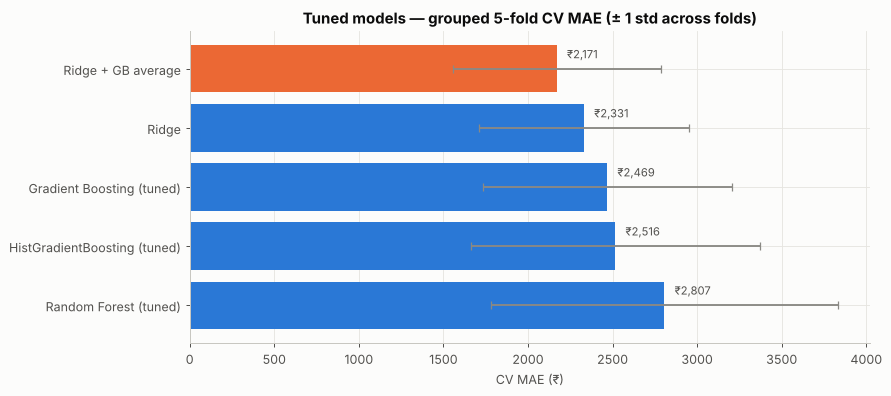

,stage,train_MAE,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,fit_time_s
model,,,,,,,
Ridge + GB average,tuned,"1,136.431","2,170.562",615.804,"4,067.131",0.847,0.115
Ridge,tuned,"1,750.038","2,331.415",621.104,"4,023.008",0.845,0.019
Ridge,default,"1,797.761","2,408.210",781.573,"4,327.602",0.828,0.019
Gradient Boosting (tuned),tuned,763.658,"2,468.637",736.110,"4,632.050",0.793,0.092
HistGradientBoosting (tuned),tuned,472.303,"2,516.450",856.115,"4,673.574",0.780,0.245
Random Forest (tuned),tuned,"1,151.035","2,806.883","1,023.518","5,156.712",0.756,0.343
Gradient Boosting,default,753.010,"2,810.053",771.807,"5,209.628",0.749,0.066
Random Forest,default,444.833,"2,958.714",995.984,"5,599.150",0.704,0.292
HistGradientBoosting,default,"1,079.755","2,961.417","1,075.131","5,309.017",0.730,0.097


In [10]:
summary = pd.concat([default_results.assign(stage="default"), tuned_results.assign(stage="tuned")])
summary = summary[["stage", "train_MAE", "cv_MAE", "cv_MAE_std", "cv_RMSE", "cv_R2", "fit_time_s"]].sort_values("cv_MAE")
summary.to_csv(PROJECT_ROOT / "reports" / "cv_model_comparison.csv")

plot = tuned_results.sort_values("cv_MAE", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(plot.index, plot["cv_MAE"], xerr=plot["cv_MAE_std"], color=[ACCENT if i == plot.index[-1] else PRIMARY for i in plot.index],
        ecolor="#8a8984", capsize=3)
for i, v in enumerate(plot["cv_MAE"]):
    ax.text(v + 60, i + 0.18, f"₹{v:,.0f}", color="#52514e", fontsize=9)
ax.set(title="Tuned models — grouped 5-fold CV MAE (± 1 std across folds)", xlabel="CV MAE (₹)")
fig.tight_layout(); save_fig(fig, "tuning_cv_comparison")
summary.round(3)

**Candidates for final validation (Day 9):**
1. **Ridge + GB average** — best CV MAE and lowest variance.
2. **Ridge** — simplest, fully interpretable, second-best CV.
3. **Tuned Gradient Boosting / HistGradientBoosting** — best single non-linear models.

Tuned parameters are recorded in `src/train.py` (`RIDGE_PARAMS`, `GB_PARAMS`, `HGB_PARAMS`, `RF_PARAMS`) and the
search log in `reports/tuning_results.csv`.